# Notebook 04 — Model Evaluation & Explainability

## Objectif

Dans ce notebook, nous allons évaluer **les six modèles individuellement**, puis les comparer avec les mêmes données de test.

Modèles étudiés :
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. KNN
5. SVM
6. Gradient Boosting

Pour chaque modèle, nous allons examiner les métriques, la matrice de confusion, le rapport de classification et les courbes ROC/Precision-Recall. Nous analyserons aussi les erreurs et l'importance des variables.

**Important :** le Notebook 03 a sauvegardé le meilleur modèle uniquement (`best_model.joblib`). Les six modèles seront donc recréés avec les mêmes paramètres et réentraînés sur `X_train_processed.csv` afin de pouvoir les comparer individuellement. Le jeu de test sert ici à l'évaluation, pas à l'entraînement.

## 1. Importation des bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
    RocCurveDisplay, precision_recall_curve, average_precision_score
)
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 2. Définition des chemins du projet

In [2]:
PROJECT_ROOT = Path.cwd()

# Si Jupyter est lancé depuis le dossier notebooks
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
EVALUATION_MODELS_DIR = MODELS_DIR / "evaluation_models"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", PROJECT_ROOT)
print("Dossier des données :", PROCESSED_DIR)
print("Dossier des modèles :", MODELS_DIR)
print("Dossier des rapports :", REPORTS_DIR)

Racine du projet : C:\Users\Octinz\Documents\automl-mlops-platform
Dossier des données : C:\Users\Octinz\Documents\automl-mlops-platform\data\processed
Dossier des modèles : C:\Users\Octinz\Documents\automl-mlops-platform\models
Dossier des rapports : C:\Users\Octinz\Documents\automl-mlops-platform\reports


## 3. Vérification et chargement des données

In [3]:
required_files = [
    PROCESSED_DIR / "X_train_processed.csv",
    PROCESSED_DIR / "X_test_processed.csv",
    PROCESSED_DIR / "y_train.csv",
    PROCESSED_DIR / "y_test.csv"
]

missing_files = [str(p) for p in required_files if not p.exists()]
if missing_files:
    raise FileNotFoundError(
        "Fichiers introuvables. Vérifiez que le Notebook 02 a été exécuté :\n"
        + "\n".join(missing_files)
    )

X_train = pd.read_csv(PROCESSED_DIR / "X_train_processed.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_processed.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Churn"].astype(int)
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")["Churn"].astype(int)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

assert list(X_train.columns) == list(X_test.columns), "Les colonnes Train et Test sont différentes."
assert not X_train.isnull().any().any(), "X_train contient des valeurs manquantes."
assert not X_test.isnull().any().any(), "X_test contient des valeurs manquantes."
assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

print("\nChargement et vérifications terminés.")

X_train : (5634, 45)
X_test  : (1409, 45)
y_train : (5634,)
y_test  : (1409,)

Chargement et vérifications terminés.


## 4. Rappel de la cible

La variable cible `Churn` a été encodée dans le Notebook 02 :

- `0` : le client reste (`No Churn`)
- `1` : le client quitte l'entreprise (`Churn`)

Nous considérons la classe `1` comme la classe positive, car détecter les clients qui risquent de partir est l'objectif principal.

In [4]:
print("Distribution de Churn dans le jeu de test :")
display(
    y_test.value_counts()
    .rename(index={0: "No Churn (0)", 1: "Churn (1)"})
    .to_frame("Nombre de clients")
)

print("\nPourcentages :")
display((y_test.value_counts(normalize=True) * 100).round(2))

Distribution de Churn dans le jeu de test :


,Nombre de clients
Churn,
No Churn (0),1035
Churn (1),374



Pourcentages :


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

## 5. Recréation des six modèles

In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

print(f"{len(models)} modèles sont prêts.")
for model_name in models:
    print("-", model_name)

6 modèles sont prêts.
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM
- Gradient Boosting


## 6. Entraînement des modèles

Le jeu d'entraînement (`X_train`, `y_train`) est utilisé pour ajuster les six modèles. Le jeu de test reste séparé pour mesurer leurs performances.

In [6]:
trained_models = {}

for name, model in models.items():
    print(f"Entraînement : {name}")
    model.fit(X_train, y_train)
    trained_models[name] = model

    # Sauvegarde individuelle du modèle entraîné
    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )
    model_path = EVALUATION_MODELS_DIR / f"{safe_name}.joblib"
    joblib.dump(model, model_path)

print("\nLes six modèles ont été entraînés et sauvegardés.")
print("Dossier :", EVALUATION_MODELS_DIR)

Entraînement : Logistic Regression
Entraînement : Decision Tree
Entraînement : Random Forest
Entraînement : KNN
Entraînement : SVM
Entraînement : Gradient Boosting

Les six modèles ont été entraînés et sauvegardés.
Dossier : C:\Users\Octinz\Documents\automl-mlops-platform\models\evaluation_models


## 7. Prédictions et métriques pour chaque modèle

Métriques calculées :
- **Accuracy** : proportion totale de prédictions correctes.
- **Precision** : parmi les clients prédits `Churn`, proportion réellement en Churn.
- **Recall** : parmi les clients réellement en Churn, proportion détectée.
- **F1-score** : moyenne harmonique entre Precision et Recall.
- **ROC-AUC** : capacité à distinguer les deux classes.

Le F1-score et le Recall sont particulièrement importants lorsque l'on veut détecter les clients susceptibles de quitter l'entreprise.

In [7]:
evaluation_results = []
predictions = {}
probabilities = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    # Tous les modèles définis dans ce notebook fournissent predict_proba
    y_proba = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_proba

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Average Precision": average_precision_score(y_test, y_proba)
    })

evaluation_df = pd.DataFrame(evaluation_results)
evaluation_df = evaluation_df.sort_values("F1-score", ascending=False).reset_index(drop=True)

display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,SVM,0.7438,0.5115,0.7727,0.6155,0.8210,0.5914
1,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416,0.6327
2,Random Forest,0.7700,0.5592,0.6310,0.5930,0.8213,0.6034
3,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433,0.6600
4,KNN,0.7637,0.5527,0.5749,0.5636,0.7896,0.5351
5,Decision Tree,0.7431,0.5168,0.4947,0.5055,0.6640,0.3905


## 8. Comparaison graphique des métriques

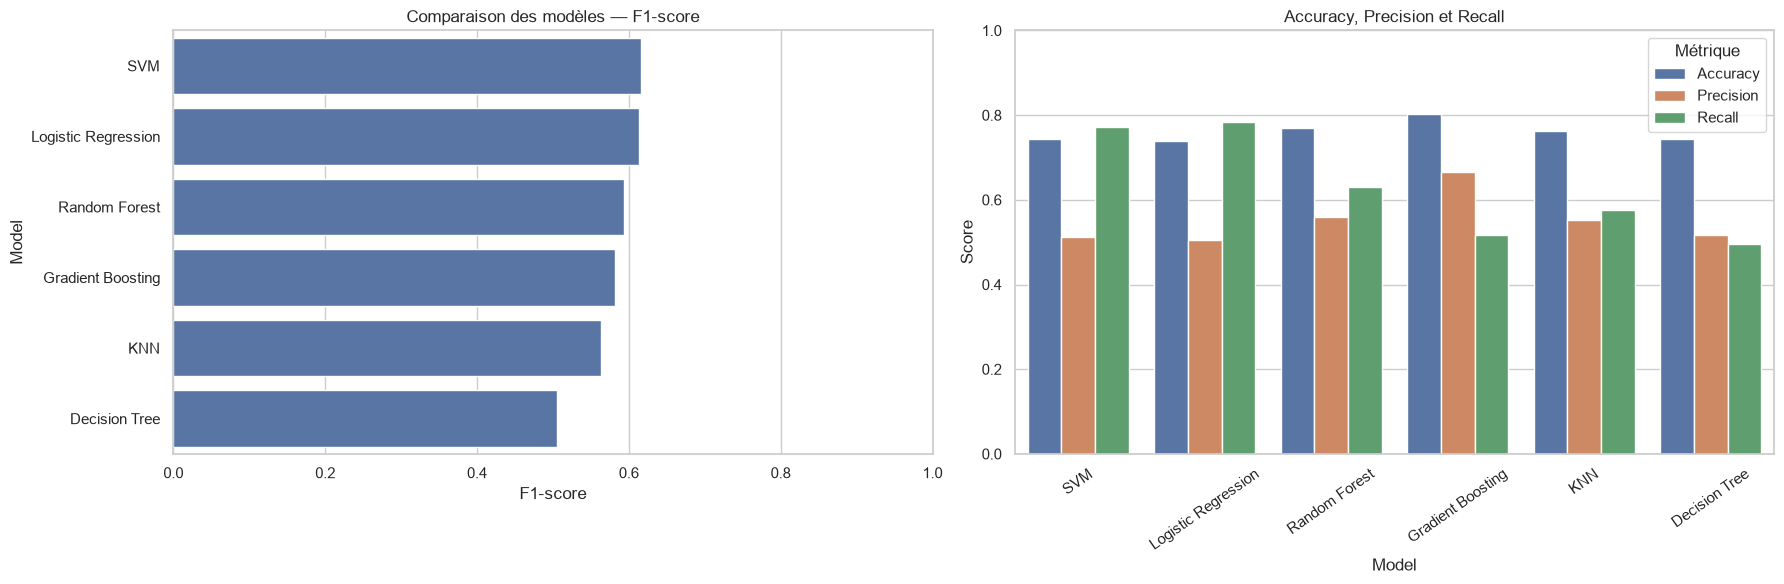

In [8]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=evaluation_df.sort_values("F1-score", ascending=False),
    x="F1-score", y="Model", ax=axes[0]
)
axes[0].set_title("Comparaison des modèles — F1-score")
axes[0].set_xlim(0, 1)

plot_df = evaluation_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall"],
    var_name="Métrique",
    value_name="Score"
)
sns.barplot(data=plot_df, x="Model", y="Score", hue="Métrique", ax=axes[1])
axes[1].set_title("Accuracy, Precision et Recall")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

## 9. Matrices de confusion — les six modèles

Une matrice de confusion contient :
- **TN (True Negative)** : client resté, correctement prédit `No Churn`.
- **FP (False Positive)** : client resté, mais prédit `Churn`.
- **FN (False Negative)** : client parti, mais prédit `No Churn`.
- **TP (True Positive)** : client parti, correctement détecté `Churn`.

Les faux négatifs sont importants à surveiller : ce sont les clients qui partent sans avoir été détectés par le modèle.

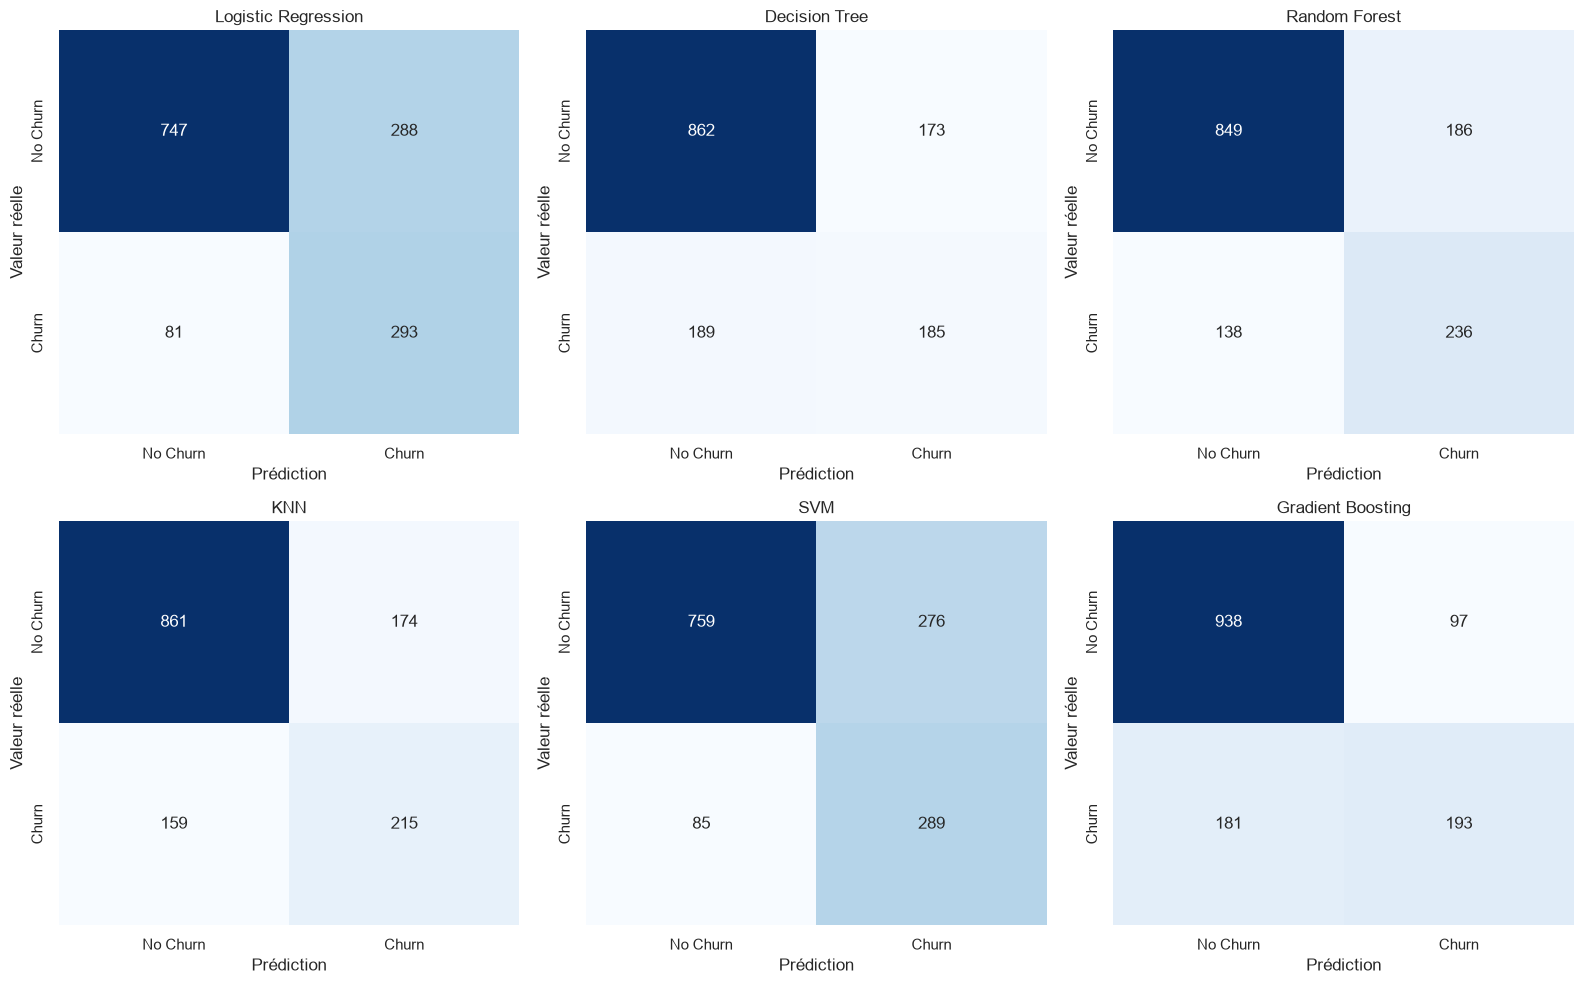

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Valeur réelle")

plt.tight_layout()
plt.show()

## 10. Rapports de classification — chaque modèle

In [10]:
for name, y_pred in predictions.items():
    print("=" * 75)
    print("MODÈLE :", name)
    print("=" * 75)
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

MODÈLE : Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

MODÈLE : Decision Tree
              precision    recall  f1-score   support

    No Churn       0.82      0.83      0.83      1035
       Churn       0.52      0.49      0.51       374

    accuracy                           0.74      1409
   macro avg       0.67      0.66      0.67      1409
weighted avg       0.74      0.74      0.74      1409

MODÈLE : Random Forest
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409

## 11. Courbes ROC — comparaison des six modèles

La courbe ROC compare le taux de vrais positifs (TPR) au taux de faux positifs (FPR) pour différents seuils de décision.

Une courbe située davantage vers le coin supérieur gauche indique généralement une meilleure séparation des classes. L'AUC résume cette capacité : plus elle est proche de 1, meilleure est la discrimination.

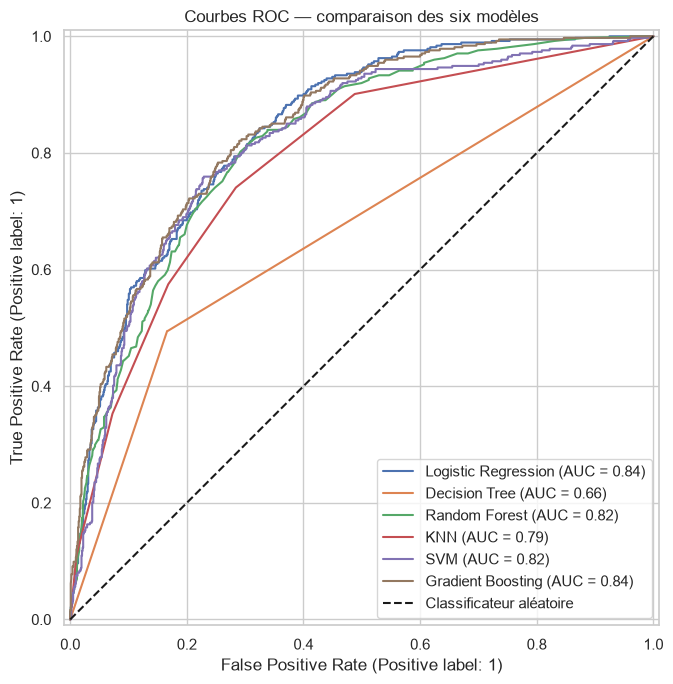

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model, X_test, y_test, name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Classificateur aléatoire")
ax.set_title("Courbes ROC — comparaison des six modèles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 12. Courbes Precision-Recall

La courbe Precision-Recall est particulièrement utile lorsque les classes sont déséquilibrées. Elle montre le compromis entre la précision et le rappel pour différents seuils.

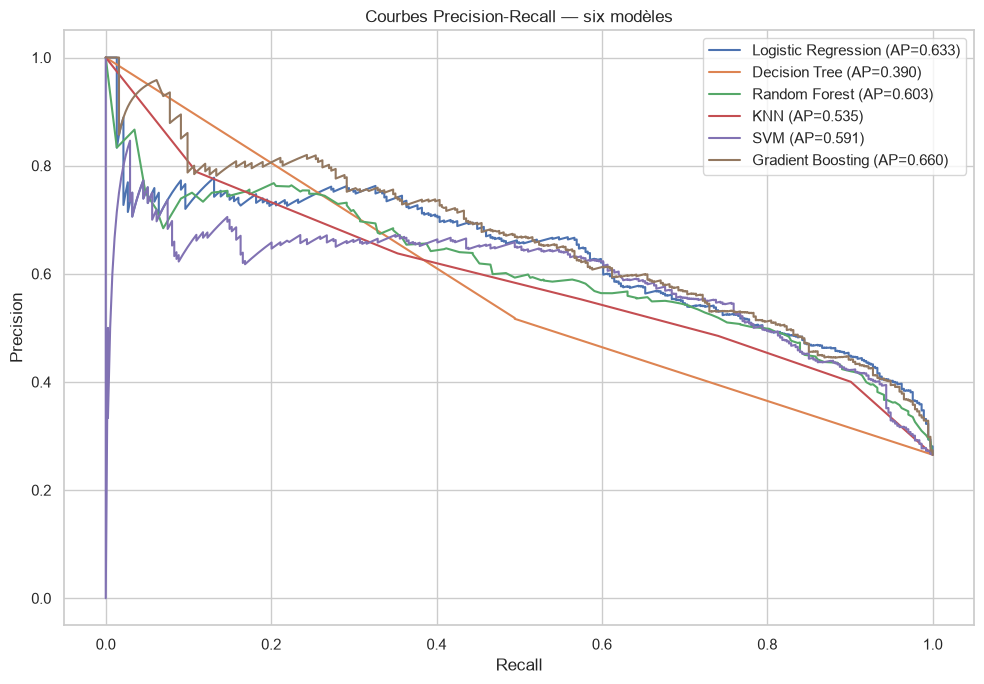

In [12]:
plt.figure(figsize=(10, 7))

for name, y_proba in probabilities.items():
    precision_values, recall_values, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    plt.plot(recall_values, precision_values, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbes Precision-Recall — six modèles")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.show()

## 13. Analyse des erreurs — False Positives et False Negatives

Nous comptons, pour chaque modèle :
- les **False Positives** : fausses alertes de départ ;
- les **False Negatives** : départs réels non détectés.

Ces deux erreurs n'ont pas le même impact métier. Une entreprise peut vouloir limiter les faux négatifs pour ne pas manquer les clients à risque, tout en contrôlant les fausses alertes.

In [13]:
error_rows = []

for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    error_rows.append({
        "Model": name,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

errors_df = pd.DataFrame(error_rows)
display(errors_df.sort_values("False Negative").reset_index(drop=True))

,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,747,288,81,293
1,SVM,759,276,85,289
2,Random Forest,849,186,138,236
3,KNN,861,174,159,215
4,Gradient Boosting,938,97,181,193
5,Decision Tree,862,173,189,185


### Visualisation des erreurs

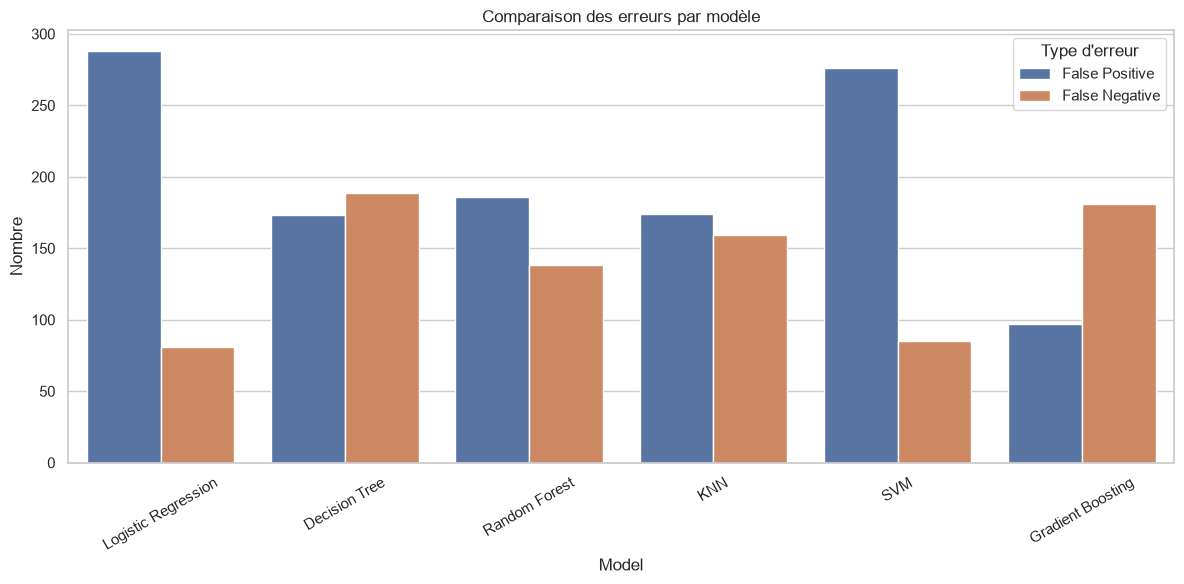

In [14]:
errors_plot = errors_df.melt(
    id_vars="Model",
    value_vars=["False Positive", "False Negative"],
    var_name="Type d'erreur",
    value_name="Nombre"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=errors_plot, x="Model", y="Nombre", hue="Type d'erreur")
plt.title("Comparaison des erreurs par modèle")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 14. Analyse des variables importantes

Les modèles basés sur des arbres possèdent une propriété `feature_importances_`. Pour Logistic Regression, nous pouvons examiner les coefficients.

**Attention :** les importances et coefficients ne prouvent pas une relation causale. Ils indiquent seulement quelles variables contribuent au fonctionnement du modèle.

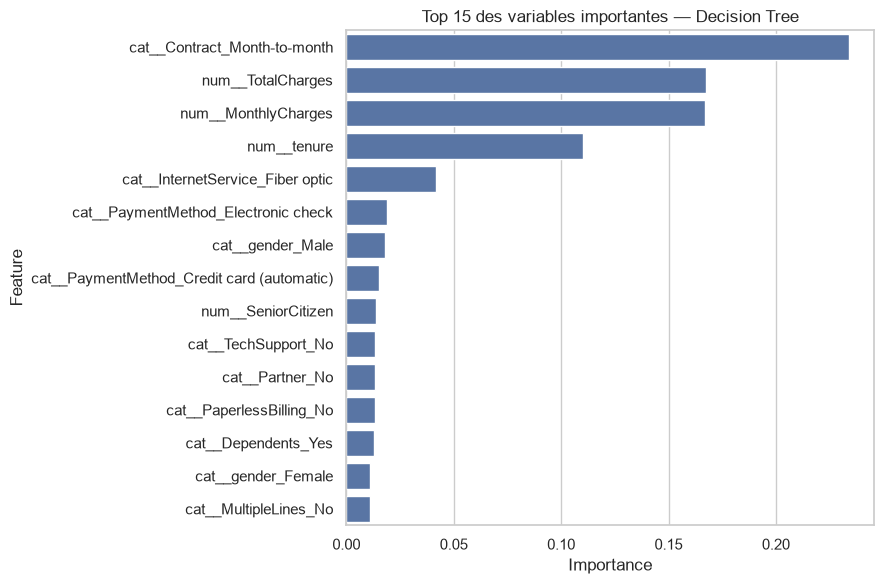

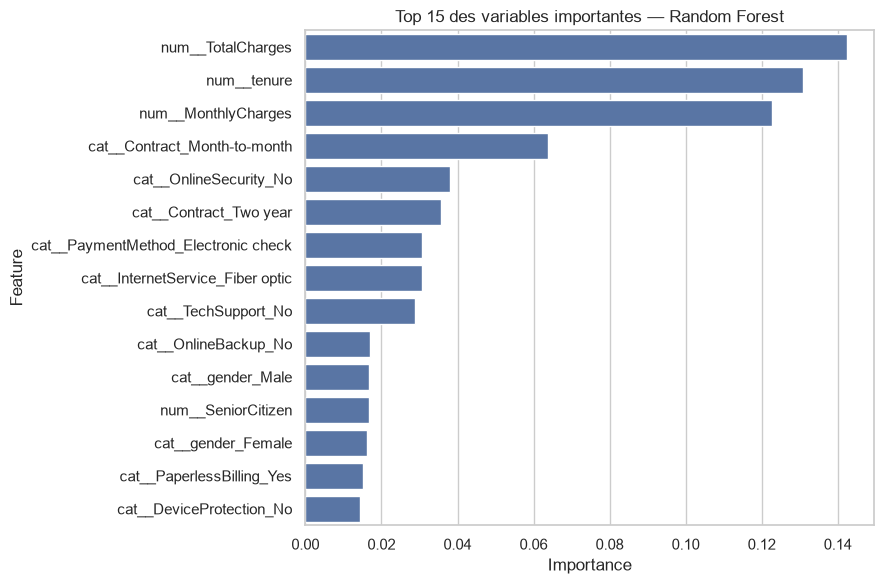

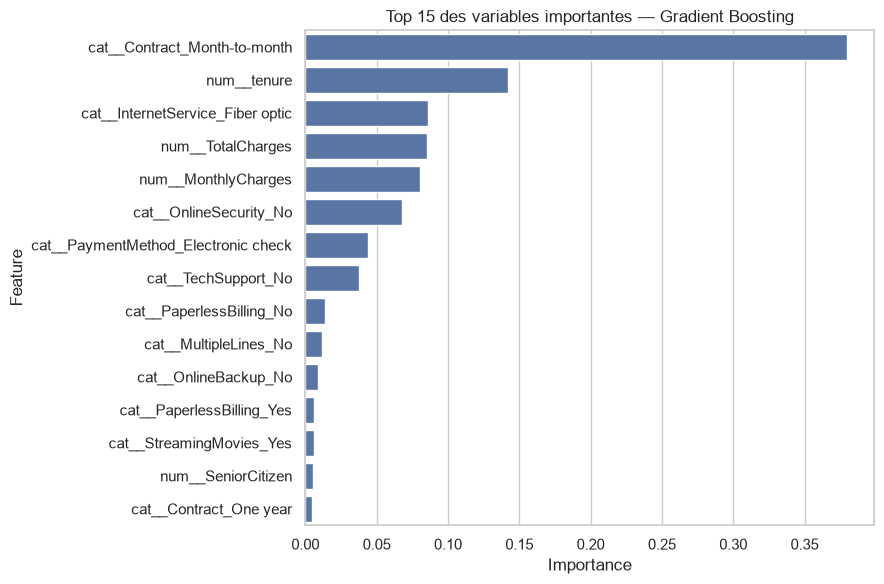

In [15]:
tree_models = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]

for name in tree_models:
    model = trained_models[name]
    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=False).head(15)

    plt.figure(figsize=(9, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top 15 des variables importantes — {name}")
    plt.tight_layout()
    plt.show()

### Coefficients de Logistic Regression

In [16]:
log_model = trained_models["Logistic Regression"]

coefficients_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_model.coef_[0]
})

coefficients_df["Abs_Coefficient"] = coefficients_df["Coefficient"].abs()
coefficients_df = coefficients_df.sort_values("Abs_Coefficient", ascending=False)

print("Variables avec les coefficients les plus positifs :")
display(
    coefficients_df.sort_values("Coefficient", ascending=False)
    .head(10)[["Feature", "Coefficient"]]
)

print("Variables avec les coefficients les plus négatifs :")
display(
    coefficients_df.sort_values("Coefficient", ascending=True)
    .head(10)[["Feature", "Coefficient"]]
)

Variables avec les coefficients les plus positifs :


,Feature,Coefficient
16,cat__InternetService_Fiber optic,0.707981
36,cat__Contract_Month-to-month,0.657713
3,num__TotalCharges,0.489698
35,cat__StreamingMovies_Yes,0.275392
32,cat__StreamingTV_Yes,0.262166
43,cat__PaymentMethod_Electronic check,0.240275
18,cat__OnlineSecurity_No,0.199030
27,cat__TechSupport_No,0.165519
14,cat__MultipleLines_Yes,0.132843
26,cat__DeviceProtection_Yes,0.074190


Variables avec les coefficients les plus négatifs :


,Feature,Coefficient
1,num__tenure,-1.154434
38,cat__Contract_Two year,-0.775518
2,num__MonthlyCharges,-0.676114
15,cat__InternetService_DSL,-0.622465
28,cat__TechSupport_No internet service,-0.275403
19,cat__OnlineSecurity_No internet service,-0.275403
17,cat__InternetService_No,-0.275403
25,cat__DeviceProtection_No internet service,-0.275403
31,cat__StreamingTV_No internet service,-0.275403
22,cat__OnlineBackup_No internet service,-0.275403


## 15. Permutation Importance du meilleur modèle selon F1-score

La permutation importance mesure la baisse de performance lorsqu'une variable est mélangée. Une forte baisse du F1-score signifie que le modèle dépend davantage de cette variable.

Cette analyse est effectuée ici sur le modèle qui obtient le F1-score le plus élevé dans cette évaluation. Les résultats doivent être interprétés comme une analyse descriptive, pas comme une preuve de causalité.

Modèle analysé : SVM


,Feature,Importance Mean,Importance Std
1,num__tenure,0.0428,0.0054
36,cat__Contract_Month-to-month,0.0185,0.0060
3,num__TotalCharges,0.0024,0.0025
0,num__SeniorCitizen,0.0019,0.0014
15,cat__InternetService_DSL,0.0010,0.0038
37,cat__Contract_One year,0.0008,0.0037
42,cat__PaymentMethod_Credit card (automatic),0.0006,0.0018
9,cat__Dependents_Yes,-0.0006,0.0008
8,cat__Dependents_No,-0.0006,0.0008
22,cat__OnlineBackup_No internet service,-0.0011,0.0014


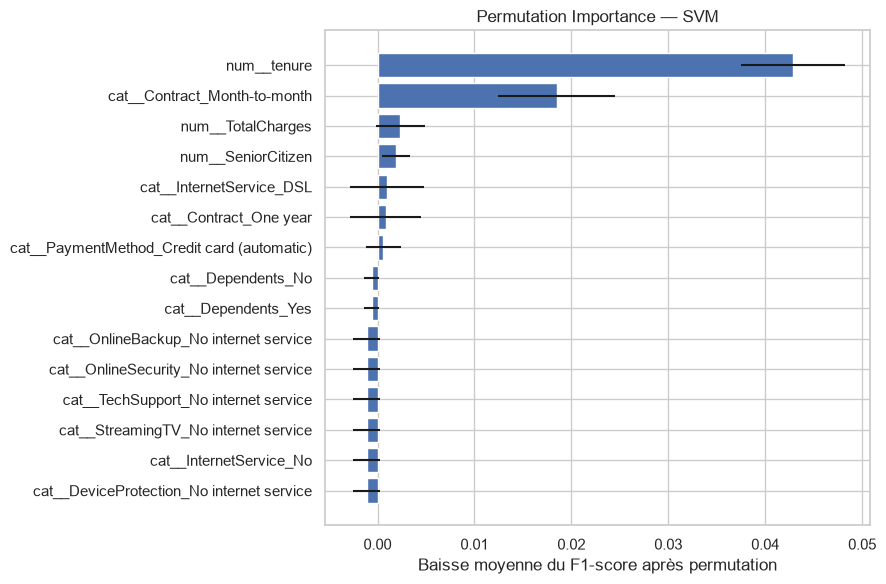

In [17]:
best_model_name = evaluation_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Modèle analysé :", best_model_name)

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values("Importance Mean", ascending=False)

display(permutation_df.head(20).round(4))

top_perm = permutation_df.head(15).sort_values("Importance Mean")
plt.figure(figsize=(9, 6))
plt.barh(top_perm["Feature"], top_perm["Importance Mean"], xerr=top_perm["Importance Std"])
plt.xlabel("Baisse moyenne du F1-score après permutation")
plt.title(f"Permutation Importance — {best_model_name}")
plt.tight_layout()
plt.show()

## 16. Synthèse automatique des résultats

Le tableau ci-dessous classe les modèles selon le F1-score. Le meilleur modèle de cette évaluation est identifié automatiquement.

**Prudence méthodologique :** ce classement décrit les performances sur ce jeu de test. Pour choisir définitivement un modèle en production, il est préférable de sélectionner le modèle sur validation/cross-validation, puis d'utiliser le test une seule fois pour l'évaluation finale.

In [18]:
best_row = evaluation_df.iloc[0]

print("Meilleur F1-score sur le jeu de test :")
print("Modèle :", best_row["Model"])
print(f"F1-score : {best_row['F1-score']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"ROC-AUC  : {best_row['ROC-AUC']:.4f}")

print("\nClassement complet :")
display(evaluation_df.round(4))

Meilleur F1-score sur le jeu de test :
Modèle : SVM
F1-score : 0.6155
Recall   : 0.7727
Precision: 0.5115
ROC-AUC  : 0.8210

Classement complet :


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,SVM,0.7438,0.5115,0.7727,0.6155,0.8210,0.5914
1,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416,0.6327
2,Random Forest,0.7700,0.5592,0.6310,0.5930,0.8213,0.6034
3,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433,0.6600
4,KNN,0.7637,0.5527,0.5749,0.5636,0.7896,0.5351
5,Decision Tree,0.7431,0.5168,0.4947,0.5055,0.6640,0.3905


## 17. Sauvegarde des résultats et des modèles

In [19]:
evaluation_path = REPORTS_DIR / "model_evaluation.csv"
errors_path = REPORTS_DIR / "model_error_analysis.csv"
permutation_path = REPORTS_DIR / "best_model_permutation_importance.csv"

evaluation_df.to_csv(evaluation_path, index=False)
errors_df.to_csv(errors_path, index=False)
permutation_df.to_csv(permutation_path, index=False)

# Sauvegarder aussi le meilleur modèle de cette évaluation
best_model_path = MODELS_DIR / "best_model_evaluated.joblib"
joblib.dump(best_model, best_model_path)

print("Fichiers sauvegardés :")
for path in [evaluation_path, errors_path, permutation_path, best_model_path]:
    print(path.relative_to(PROJECT_ROOT), "->", path.exists())

Fichiers sauvegardés :
reports\model_evaluation.csv -> True
reports\model_error_analysis.csv -> True
reports\best_model_permutation_importance.csv -> True
models\best_model_evaluated.joblib -> True


## 18. Vérification finale des fichiers")

In [20]:
print("Rapports générés :")
for path in [evaluation_path, errors_path, permutation_path]:
    print("-", path.name, ":", path.exists())

print("\nModèles entraînés sauvegardés :")
for path in sorted(EVALUATION_MODELS_DIR.glob("*.joblib")):
    print("-", path.name)

print("\nMeilleur modèle évalué :", best_model_path.exists())

Rapports générés :
- model_evaluation.csv : True
- model_error_analysis.csv : True
- best_model_permutation_importance.csv : True

Modèles entraînés sauvegardés :
- decision_tree.joblib
- gradient_boosting.joblib
- knn.joblib
- logistic_regression.joblib
- random_forest.joblib
- svm.joblib

Meilleur modèle évalué : True


In [21]:
import joblib

model = joblib.load("../models/best_model_evaluated.joblib")

print(type(model))
print(model)

<class 'sklearn.svm._classes.SVC'>
SVC(class_weight='balanced', probability=True, random_state=42)


# Conclusion

Dans ce notebook, nous avons évalué individuellement les six modèles de classification du Churn.

Nous avons :
- recalculé Accuracy, Precision, Recall, F1-score, ROC-AUC et Average Precision ;
- étudié les matrices de confusion et les rapports de classification ;
- comparé les courbes ROC et Precision-Recall ;
- analysé les faux positifs et les faux négatifs ;
- étudié les variables importantes avec les importances des arbres, les coefficients de Logistic Regression et la permutation importance ;
- sauvegardé les résultats et les modèles entraînés.

**À retenir :** le meilleur modèle ne doit pas être choisi uniquement selon Accuracy. Dans le contexte du Churn, Recall et F1-score sont également importants. La décision finale doit tenir compte des objectifs métier et être confirmée avec une validation rigoureuse.